# DDRL Actor-Critic {#sec-ddrlac}

In this section, we provide functions that are specific to the Actor-Critic version of Distributional Deterministic Reinforcement Learning.

First, we import everything necessary:

In [ ]:
#| default_exp Agents/DDRLActorCritic

In [ ]:
#| hide
# Imports for the nbdev development environment
import nbdev
from nbdev.showdoc import *
from fastcore.basics import patch

In [ ]:
#| export
import numpy as np
from scipy.stats import norm

import jax.numpy as jnp
from jax import jit
from functools import partial

import itertools as it

from pyCRLD.Agents.Base import abase
from pyCRLD.Utils.Helpers import *
from pyCRLD.Utils.Helpers import compute_stationarydistribution

from pyDDRL.Agents.DDRLBase import DDRLBase

from pyDDRL.Agents.Methods import quantile, expectile, weights

In [ ]:
# imports for this notebook
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from pyCRLD.Utils import FlowPlot as fp

# test environment
from pyDDRL.Environments.RiskRewardDilemma import RiskRewardDilemma

# regular Actor-Critic agent
from pyCRLD.Agents.StrategyActorCritic import stratAC

## Test environment

We use a risk-reward dilemma as a test environment. In this task, the agent can choose between a high-risk, high-gain option, and a low-risk, low-gain option. More precisely, we give our environment the following structure:

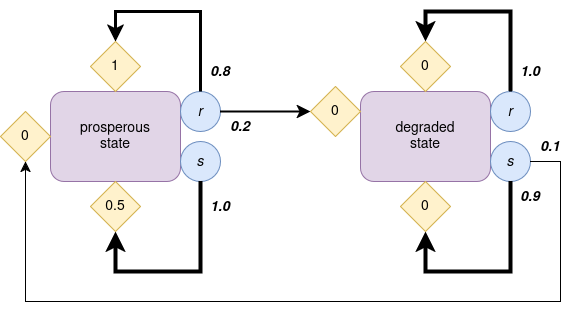

If an agent chooses the risky action $r$ in the prosperous state, it gets a higher reward. But there is a probability that it transitions to a degraded state, where it gets no reward. The only way to escape this degraded state is to choose the safe action, $s$.

In [ ]:
# Define environment
env = RiskRewardDilemma(pc=0.1, pr=0.2, rc=0.5, rr=1, rd=0)
env

RiskRewardDilemma_0.1_0.2_0.5_1_0

## DDRL Actor-Critic class

Now, we can define the DDRL Actor-Critic class:

In [ ]:
#| export
class DDRLActorCritic(DDRLBase):
    """
    Base class for Actor-Critic version of DDRL in strategy space.        
    """
    
    def __init__(self,
                 env,
                 **kwargs):
    
        super().__init__(env, **kwargs)

We consider the following agent-environment interface:
* 1 agent with learning rate $\alpha=0.1$ and discount factor $\gamma=0.4$;
* playing the aforementioned risk-reward dilemma.

In [ ]:
aei = DDRLActorCritic(env,
                      nr_reward_bins=29,
                      discretization_sigma=0.1,
                      learning_rates=0.1,
                      discount_factors=0.4,
                      Rmin=-0.5,
                      Rmax=1.5,
                      use_prefactor=True)

No GPU/TPU found, falling back to CPU. (Set TF_CPP_MIN_LOG_LEVEL=0 and rerun for more info.)


In [ ]:
#| export
@partial(jit, static_argnums=0)
def NextVisa(self:DDRLActorCritic,
             Xisa,      # Joint strategy
             Vis=None,  # Optional values for speed-up
             Tss=None,  # Optional transition for speed-up
             Ris=None,  # Optional reward for speed-up
             Risa=None  # Optional reward for speed-up
             ) -> jnp.ndarray: # Next values
    """
    Compute strategy-average next value for agent `i`, current state `s` and action `a`.
    """
    Vis = self.Vis(Xisa) if Vis is None else Vis
        
    i = 0; a = 1; s = 2; s_ = 3
    j2k = list(range(6, 6+self.N-1))  # other agents
    b2d = list(range(6+self.N-1, 6+self.N-1 + self.N))  # all actions
    e2f = list(range(5+2*self.N, 5+2*self.N + self.N-1))  # all other acts

    sumsis = [[j2k[l], s, e2f[l]] for l in range(self.N-1)]  # sum inds
    otherX = list(it.chain(*zip((self.N-1)*[Xisa], sumsis)))
                                
    args = [self.Omega, [i]+j2k+[a]+b2d+e2f] + otherX +\
        [self.T, [s]+b2d+[s_], Vis, [i, s_], [i, s, a]]
    return jnp.einsum(*args, optimize=self.opti)

DDRLActorCritic.NextVisa = NextVisa

In [ ]:
#| export
@partial(jit, static_argnums=0)        
def Visav(self:DDRLActorCritic,
          Xisa:jnp.ndarray, # Joint strategy
          Tisas:jnp.ndarray=None, # Optional transition for speed-up
          ) -> jnp.ndarray:  # Average state-action values
    """
    Compute Q-value distribution Qisaq, given joint strategy `Xisa`.
    """
    Risar = self.Risar(Xisa)
    b_ivrv_ = self.b_ivrv_
    Visv = self.Visv(Xisa) 
    Tisas = self.Tisas(Xisa) if Tisas is None else Tisas 

    i = 0; s = 1; a = 2; s_ = 3; v = 4; v_ = 5; r = 6
    nextVisav = jnp.einsum(Tisas, [i,s,a,s_], Visv, [i,s_,v], [i,s,a,v],
                           optimize=self.opti)

    Visav = jnp.einsum(b_ivrv_, [i,v,r,v_], Risar, [i,s,a,r], nextVisav, [i,s,a,v_], [i,s,a,v])
    
    return Visav

DDRLActorCritic.Visav = Visav

In [ ]:
#| export
@partial(jit, static_argnums=0)        
def Visa(self,
          Xisa:jnp.ndarray, # Joint strategy
          ) -> jnp.ndarray:  # Average state-action values
    """
    Compute Q-value for state `s` and action `a`.
    """
    Visav = self.Visav(Xisa)  # Q-value distrib
    gpoints = jnp.ones((self.nr)) * -1
    gpoints = gpoints.at[:].set(self.gridpoints)
    Visa = jnp.einsum('ijkl,l->ijk', Visav, gpoints)
    i = 0; a = 1; s = 2
    Vis = jnp.einsum(Visa, [i, s, a], Xisa, [i, s, a], [i, s])
    # Baseline: mean of Qisaq
    Vis_expanded = jnp.expand_dims(Vis, axis=2)  # shape (N, Z, 1)
    baseline = jnp.repeat(Vis_expanded, self.M, axis=2)  # shape (N, Z, M)
    if self.method=='mean':  # take mean
        return Visa
    elif self.method=='quantile':  # use quantile
        return quantile(self.tau, Visav, gpoints)
    elif self.method=='expectile':  # use expectile
        return expectile(self.tau, Visav, gpoints)
    elif self.method=='weights':  # use weights
        w = jnp.ones((self.N, self.Z, self.M, len(self.gridpoints)))
        n = jnp.newaxis
        upper = self.gridpoints[n,n,n,:] >= baseline[:,:,:,n]
        upper = upper * (self.wU - 1)
        w = w + upper
        wVisav = weights(w, Visav, gpoints)
        Visa = jnp.einsum('ijkl,l->ijk', wVisav, gpoints)  # take the new distrib's mean
        return Visa

DDRLActorCritic.Visa = Visa 

In [ ]:
#|export
@partial(jit, static_argnums=(0,2))
def TDerror(self:DDRLActorCritic,
            Xisa,  # Behavior profiles
            norm=False) -> jnp.ndarray:
    """
    Compute reward-prediction/temporal-difference error for 
    strategy actor-critic dynamics, given joint strategy `Xisa`.
    """
    V = self.Visa(Xisa)
    n = jnp.newaxis
    E = V
    E *= self.beta[:,n,n]

    E = E - E.mean(axis=2, keepdims=True) if norm else E
    return E

DDRLActorCritic.TDerror = TDerror

In [ ]:
## Functions to plot 3 flowplots and associated trajectories

# Plot the flowplots together
def plot_3flowplots(aeis,  # list of aeis
                    x:tuple,  # which phase space axes to plot along x axes
                    y:tuple,  # which phase space axes to plot along y axes
                    NrRandom:int=4,  # number of random strategies to average over
                    Xinits=None,  # initial Xs to plot trajectories
                    decorate=False,  # whether to decorate the axes or not
                    titles=None,  # list of titles for 3 plots
                    xlabel=None,  # x-label
                    ylabel=None,  # y-label
                    cols=None,  # list of colors for trajectories
                    cmap='viridis',  # Colormap
                    axes=None,  # Axes to plot into
                    ):
    
    # Style
    sns.set_style("white")
    sns.set_context("paper", font_scale=1.25, rc={"lines.linewidth": 2})
    
    # Plot the flow plot
    for i, ax in enumerate(axes):
        aei = aeis[i]
        fp.plot_strategy_flow(aei, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), 
                              NrRandom=NrRandom, cmap=cmap, axes=ax)
        
        # Plot trajectory if initial strategies are specified
        if Xinits != None:
            trajs = []  # trajectories
            fprs = []  # are fixed points reached?
            for _, Xinit in enumerate(Xinits):
                trj, fpr = aei.trajectory(Xinit, Tmax=2500, tolerance=1e-6)
                trajs.append(trj)
                fprs.append(fpr)
                
            fp.plot_trajectories(trajs, x, y, fprs=fprs, axes=ax, cols=cols)
    
    # Add titles, xlabels and ylabels to subplots if needed
    if decorate==True:
        for i, ax in enumerate(axes): 
            ax.set_xlabel(xlabel)
            ax.set_title(titles[i])
        
        ax1.set_ylabel(ylabel)

In [ ]:
# Values of gamma
gammas = [0., 0.4, 0.9]

In [ ]:
# Define agents to compare
aeis_reg = []  # regular SARSA agents
aeis_ddrl = []  # DDRLSarsa agents

for i, gamma in enumerate(gammas):
    aei_reg = stratAC(env=env, learning_rates=0.1, discount_factors=gamma, 
                      use_prefactor=True)
    aeis_reg.append(aei_reg)
    
    aei_ddrl = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=0.05, 
                               learning_rates=0.1, discount_factors=gamma, 
                               Rmin=0, Rmax=1, method="mean", use_prefactor=True)
    aeis_ddrl.append(aei_ddrl)

<matplotlib.legend.Legend>

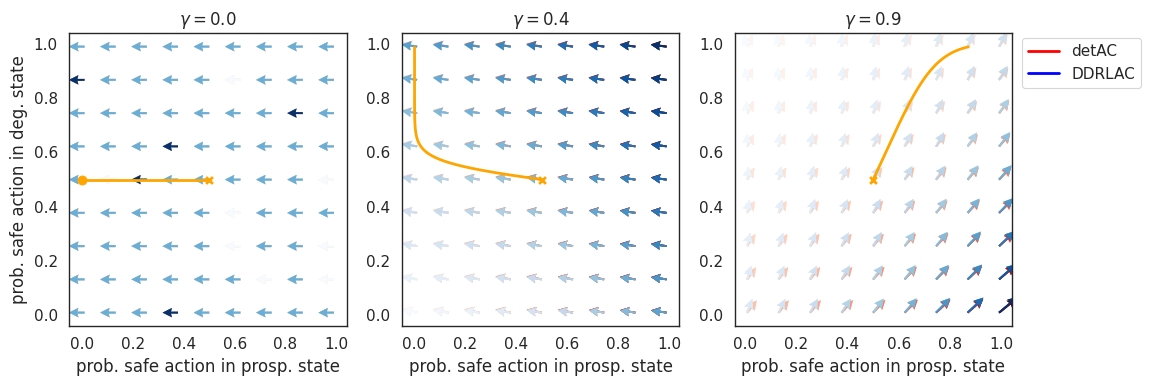

In [ ]:
# Phase space items to plot along the x- and y- axes
x = ([0], [0], [0])  # prosperous state
y = ([0], [1], [0])  # degraded state

# For trajectories
Xinits = [np.ones((1, 2, 2)) * 0.5]  # initial strategy
cols = ["orange"]  # trajectory color

# Decorations
titles = [r'$\gamma = 0.0$', r'$\gamma = 0.4$', r'$\gamma = 0.9$']
xlabel = "prob. safe action in prosp. state"
ylabel = "prob. safe action in deg. state"

# Figure and axes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(3.2 * 3.8, 3.8))
axes = [ax1, ax2, ax3]

# Plot flow plots and trajectories
plot_3flowplots(aeis_reg, x, y, NrRandom=16, cmap='Reds', axes=axes)
plot_3flowplots(aeis_ddrl, x, y, NrRandom=16, cmap='Blues', decorate=True,
                titles=titles, xlabel=xlabel, ylabel=ylabel,
                Xinits=Xinits, cols=cols, axes=axes)

# Additional decorations
ax3.plot([], [], color='red', label='detAC')
ax3.plot([], [], color='blue', label='DDRLAC')
ax3.legend(bbox_to_anchor=(1.01, 1.01))

In [ ]:
# Define agents to compare
aeis_ddrl = []  # DDRLSarsa agents

for i, gamma in enumerate(gammas):
    aei_ddrl = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=0.05, 
                               learning_rates=0.1, discount_factors=gamma, Rmin=0, 
                               Rmax=1, method="weights", wU=1., use_prefactor=True)
    aeis_ddrl.append(aei_ddrl)

<matplotlib.legend.Legend>

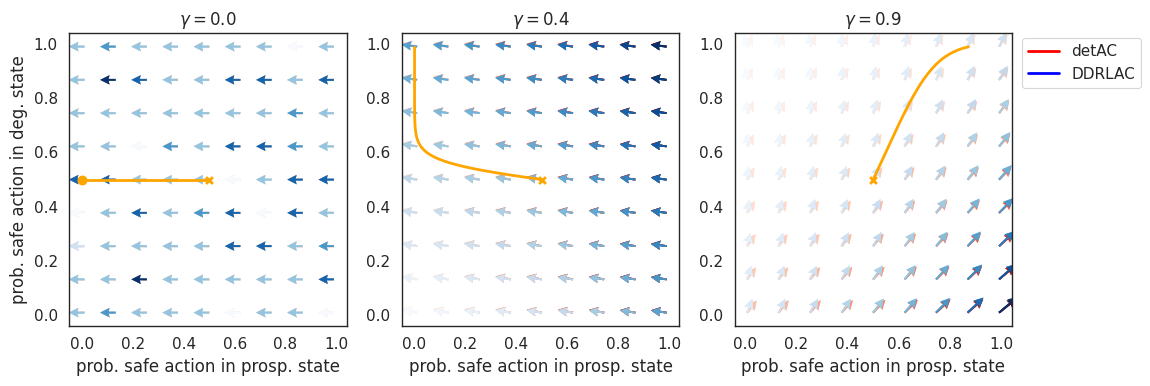

In [ ]:
# Figure and axes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(3.2 * 3.8, 3.8))
axes = [ax1, ax2, ax3]

# Plot flow plots and trajectories
plot_3flowplots(aeis_reg, x, y, NrRandom=16, cmap='Reds', axes=axes)
plot_3flowplots(aeis_ddrl, x, y, NrRandom=16, cmap='Blues', decorate=True,
                titles=titles, xlabel=xlabel, ylabel=ylabel,
                Xinits=Xinits, cols=cols, axes=axes)

# Additional decorations
ax3.plot([], [], color='red', label='detAC')
ax3.plot([], [], color='blue', label='DDRLAC')
ax3.legend(bbox_to_anchor=(1.01, 1.01))

In [ ]:
x = ([0], [0], [0])  # prosperous state
y = ([0], [1], [0])  # degraded state
w_list = [0.2, 1, 5]  # list of weights

In [ ]:
# Define agents to compare
aeis = [] # DDRLSarsa agents

for i, w in enumerate(w_list):
    aei = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=0.05, 
                          learning_rates=0.1, discount_factors=0.9, Rmin=0, 
                          Rmax=1, method="weights", wU=w, use_prefactor=True)
    aeis.append(aei)

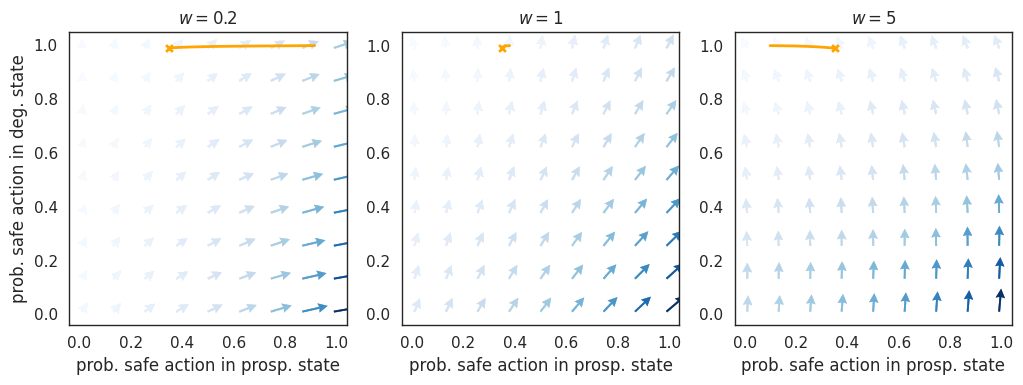

In [ ]:
# For trajectories
Xinit = np.ones((1, 2, 2)) * 0.5
Xinit[0, 0, 0] = 0.35
Xinit[0, 0, 1] = 1 - Xinit[0, 0, 0]
Xinit[0, 1, 0] = 0.99
Xinit[0, 1, 1] = 1 - Xinit[0, 1, 0]
Xinits = [Xinit]  # initial strategy
cols = ["orange"]  # trajectory color

# Decorations
titles = [r'$w = 0.2$', r'$w = 1$', r'$w = 5$']
xlabel = "prob. safe action in prosp. state"
ylabel = "prob. safe action in deg. state"

# Figure and axes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(3.2 * 3.8, 3.8))
axes = [ax1, ax2, ax3]

# Plot flow plots and trajectories
plot_3flowplots(aeis, x, y, NrRandom=16, cmap='Blues', decorate=True,
                titles=titles, xlabel=xlabel, ylabel=ylabel,
                Xinits=Xinits, cols=cols, axes=axes)

In [ ]:
# Define agents to compare
aeis = [] # DDRLSarsa agents

for i, w in enumerate(w_list):
    aei = DDRLActorCritic(env, nr_reward_bins=29, discretization_sigma=0.05, 
                          learning_rates=0.1, discount_factors=0.4, Rmin=0, 
                          Rmax=1, method="weights", wU=w, use_prefactor=True)
    aeis.append(aei)

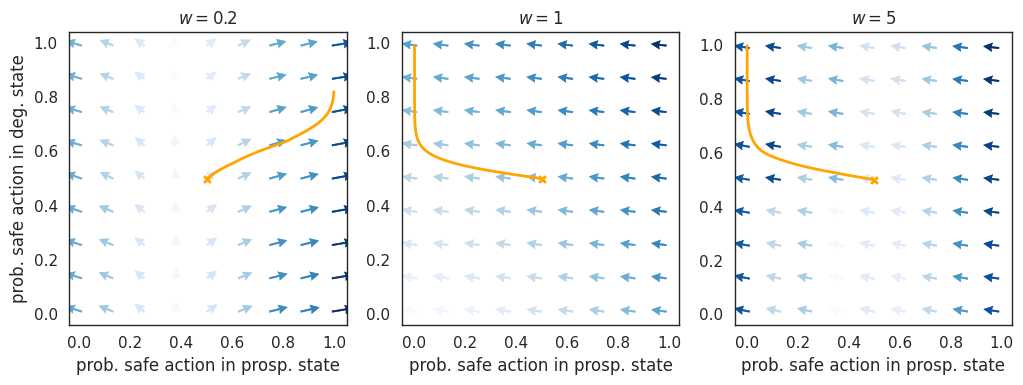

In [ ]:
# For trajectories
Xinits = [np.ones((1, 2, 2)) * 0.5]  # initial strategy
cols = ["orange"]  # trajectory color

# Decorations
titles = [r'$w = 0.2$', r'$w = 1$', r'$w = 5$']
xlabel = "prob. safe action in prosp. state"
ylabel = "prob. safe action in deg. state"

# Figure and axes
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(3.2 * 3.8, 3.8))
axes = [ax1, ax2, ax3]

# Plot flow plots and trajectories
plot_3flowplots(aeis, x, y, NrRandom=16, cmap='Blues', decorate=True,
                titles=titles, xlabel=xlabel, ylabel=ylabel,
                Xinits=Xinits, cols=cols, axes=axes)

In [ ]:
## Functions to generate phase plots + trajs + mean rewards

# Obtain dX as a function of X for phase plots
# Also works when N=2 or Z=2
def obtain_dXs(aei,  # agent-environment interface
               res,  # range & resolution of strategies
               xinds:tuple,  # of indices of the phase space object to plot along the x axis
               traj_len:int,  # trajectory len
               otherXs=None,  # when N=2 or Z=2: values of X in 2nd condition
               ):
        
    l = len(res)
    dXs = np.zeros((aei.Z, l))  # will store the dXs

    for i in range(aei.Z):
        
        for j, xval in enumerate(res):  # loop over Xs
            
            if (aei.N > 1) or (aei.Z > 1): # 2 states or 2 actions
                xval_ = otherXs[j]
            else:
                xval_ = None
                
            X = obtain_Xs(aei, xinds, xval, xval_)  # create X with values along all dims
            prederror = aei.TDerror(X, norm=True)  # compute pred error
            dX = aei.step(X)[0] - X  # compute dX
            dXs[i, j] = dX[xinds[0], i, xinds[2]]  # dX for i,s,a of interest
            
    return dXs


def obtain_Xs(aei,  # CRLD multi-agent environment object
              xinds:tuple,  # of indices of the phase space item to plot along the x axis
              xval:float,  # the value of the phase space item to plot along the x axis
              xval_:float  # the value of X in the 2nd condition
              ): 
    
    N, C, M = aei.N, aei.Z, aei.M  # Number of agents, states, actions
    
    Xs = np.zeros((N, C, M))  # will store the Xs
    
    xi, xc, xa = xinds  # plotted agent, state, action
    xa_ = tuple(set(range(M)) - set(xa))  # other action
    
    Xs[xi, xc, xa] = xval  # setting x value
    
    # probability of taking other action
    Xs[xi,xc,xa_] = 1-Xs[xi, xc, xa]
    
    if C > 1:  # more than one state
        xc_ = tuple(set(range(C)) - set(xc))  # other state
        Xs[xi, xc_, xa] = xval_  # strategy in state 2 for action 1
        Xs[xi, xc_, xa_] = 1 - Xs[xi, xc_, xa]  # strategy in state 2 for action 2
    if N > 1:  # more than 1 agent
        xi_ = tuple(set(range(N)) - set(xi))  # other agent
        Xs[xi_, xc, xa] = xval_  # other agent's strategy for action 1
        Xs[xi_, xc, xa_] = 1 - Xs[xi_, xc, xa]  # other agent's strat for action 2
    
    return Xs

# Compute X traj and reward traj
def reward_traj(aei,  # CRLD multi-agent environment object
                X:tuple,  # strategy
                i,  # agent
                traj_len:int=500,  # trajectory length
                ): 
    
    r_traj = np.zeros((traj_len))  # will store rewards
    # Compute X trajectory
    traj, fpreached = aei.trajectory(X, traj_len) 
    # Compute reward trajectory
    for t in range(traj_len):
        r_traj[t] = aei.Ri(traj[t,...])[i]
        
    return traj, r_traj
    
# Plot phase plot, X traj and reward traj for various levels of optimism/pessimism
def compare_levels(env,  # environment
                   level_list,  # list of levels
                   gamma,  # discount factor
                   Rmin,  # min reward perceived
                   Rmax,  # max reward perceived
                   xinds:tuple,  # which phase space axes to plot along x axes
                   res,  # specify range & resolution
                   nrb:int=29,  # number of neurons
                   discsig:float=0.05,  # discretization sigma
                   lr:float=0.1,  # learning rate
                   traj_len:int=500,  # trajectory length
                   otherXs=None,  # if 2nd condition: values of X along this condition
                   cmap='viridis',  # colormap
                   save=False,  # save fig?
                   savename=None,  # saved figure's name
                   axes=None,  # Axes to plot into
                   ):  
   

    # Fig and Axes
    # Style
    sns.set_style("whitegrid")
    sns.set_context("paper", font_scale=1.5, rc={"lines.linewidth": 2})
    
    # Subplots: phase plot, X traj, reward traj
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(4.5 * 3.8, 3.8))
    
    # Colormap for the different lines
    cmap = mpl.colormaps[cmap]
    ext = np.linspace(0, 1, len(level_list))  # extent of colormap
    colors = cmap(tuple(ext))
    # Neutral agent is represented with a black line
    colors[int(len(level_list)/2)] = [0, 0, 0, 1]  
    
    # Zero line
    zero = np.zeros((len(res))) 

    # Loop over optimism/pessimism levels
    for j, level in enumerate(level_list):
        
        # Define agent-environment interface
        aei = DDRLActorCritic(env, nr_reward_bins=nrb, discretization_sigma=discsig, 
                              learning_rates=lr, discount_factors=gamma, 
                              Rmin=Rmin, Rmax=Rmax,
                              method="weights", wU=level, use_prefactor=True)
 
        # Obtain the dXs for y-axis of phase plot
        dXs = obtain_dXs(aei, res, xinds, traj_len, otherXs)
        
        # Phase plot
        ax1.plot(res, dXs[0, :], color=colors[j])
        ax1.plot(res, zero, color="grey", ls='dashed')  # plot zero line
        
        # Obtain X traj and reward traj
        X0 = np.ones((aei.N, aei.Z, aei.M)) * 0.5  # init random strategy
        X_traj, r_traj = reward_traj(aei, X0, 0, traj_len=traj_len)
        
        # X traj plot
        ax2.plot(np.arange(0, traj_len), X_traj[:,0,0,0], 
                 color=colors[j], label=r'$w_{U}=$'+str(level))
        
        # Reward plot
        ax3.plot(np.arange(0, traj_len), r_traj, 
                 color=colors[j], label=r'$w_{U}=$'+str(level))
        
    # Decorations
    ax1.set_ylabel(r"$dX$")
    ax1.set_xlabel("strategy "+r'$X$')
    ax1.set_title('phase plot')
    ax2.set_xlabel("time step "+r'$t$')
    ax2.set_ylabel("strategy "+r'$X^{0,0,0}(t)$')
    ax2.set_title('strategy over time')
    ax3.set_xlabel("time step "+r'$t$')
    ax3.set_ylabel("reward "+r'$R^{0}(t)$')
    ax3.set_title('mean reward over time')
    ax3.legend(bbox_to_anchor=(1.01, 1.01), title='weights '+r'$w_U$')
    fig.tight_layout()
    
    # Save figure
    if save == True:
        plt.savefig(savename, dpi=300, bbox_inches='tight')

In [ ]:
# Levels of optimism/pessimism (defined by upper weight values w_U)
ws = np.array([0.1, 0.2, 0.4, 0.8, 1., 2., 4., 8., 10.])

# Phase space items to plot along the x-axis
x = ([0], [0], [0]) 

# Range and resolution
res = np.linspace(0, 1., 21)
res[0] = 0.0001
res[-1] = 0.9999

# Value of X^{0,1,0}
otherXs = np.ones((len(res)))

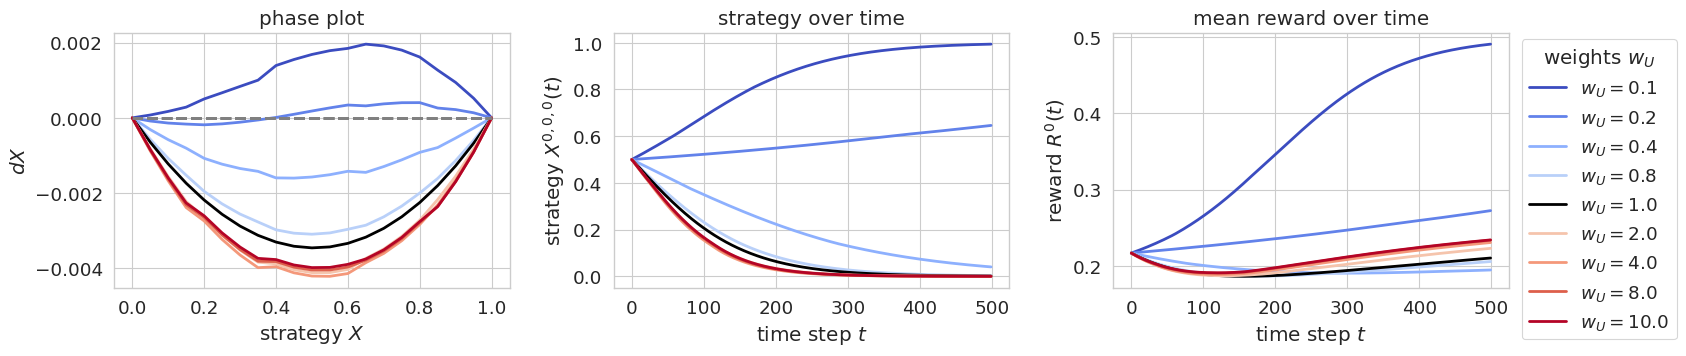

In [ ]:
# Plot and save - gamma = 0.4
compare_levels(env, ws, gamma=0.4, Rmin=0, 
               Rmax=1, xinds=x, res=res, nrb=29, discsig=0.05, 
               traj_len=500, otherXs=otherXs, cmap='coolwarm')

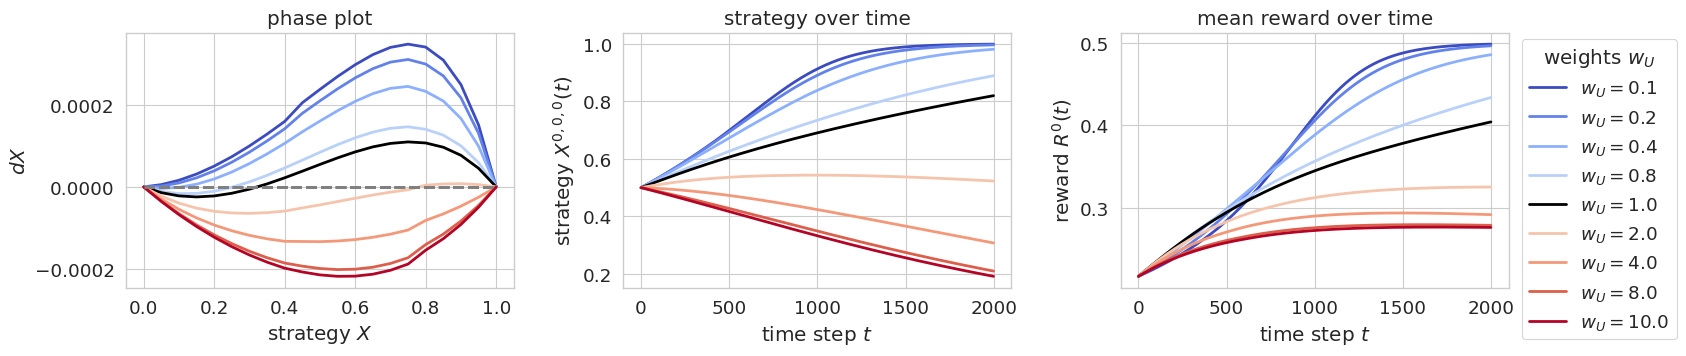

In [ ]:
# Plot and save - gamma = 0.9
compare_levels(env, ws, gamma=0.9, Rmin=0, 
               Rmax=1, xinds=x, res=res, nrb=29, discsig=0.05, 
               traj_len=2000, otherXs=otherXs, cmap='coolwarm')

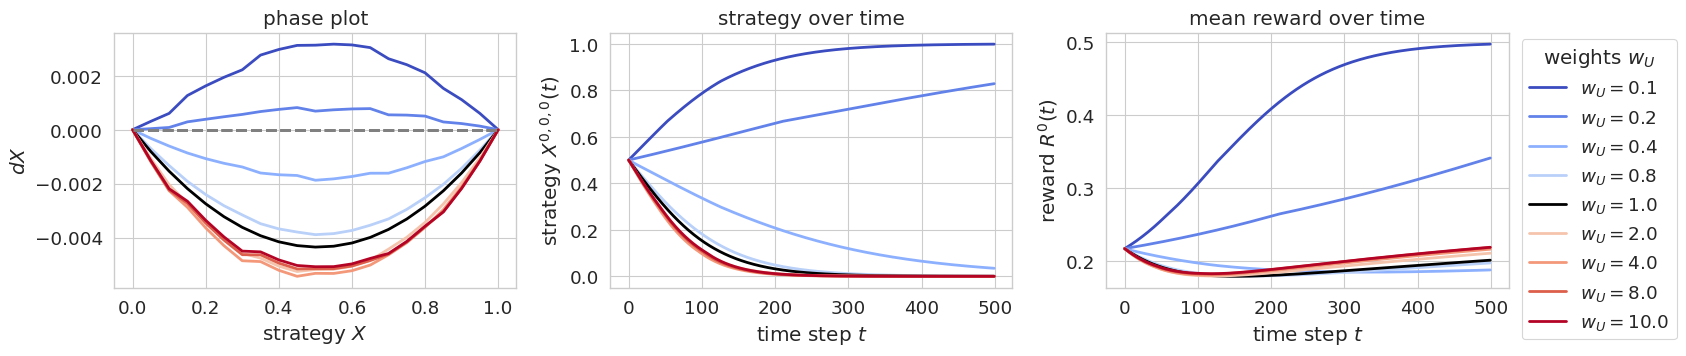

In [ ]:
# Plot and save - gamma = 0.3
compare_levels(env, ws, gamma=0.3, Rmin=0, 
               Rmax=1, xinds=x, res=res, nrb=29, discsig=0.05, 
               traj_len=500, otherXs=otherXs, cmap='coolwarm')

In [ ]:
nbdev.export.nb_export("02.03_DDRLActorCritic.ipynb", "")